In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def compute_FC(zon_group_velocity, u_0, alpha, beta, density_weighted_stat_lwa):

    lat = zon_group_velocity['lat']
    cosphi = np.cos(np.deg2rad(lat)).broadcast_like(zon_group_velocity)
    
    # intermediate
    u = zon_group_velocity + u_0 + beta - 2*alpha*density_weighted_stat_lwa
    
    #computed FC
    FC = (u**2 * cosphi) / (4.0 * alpha)
    return FC



In [3]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []

for i,experiment in enumerate(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
    ds_clims.append(ds)

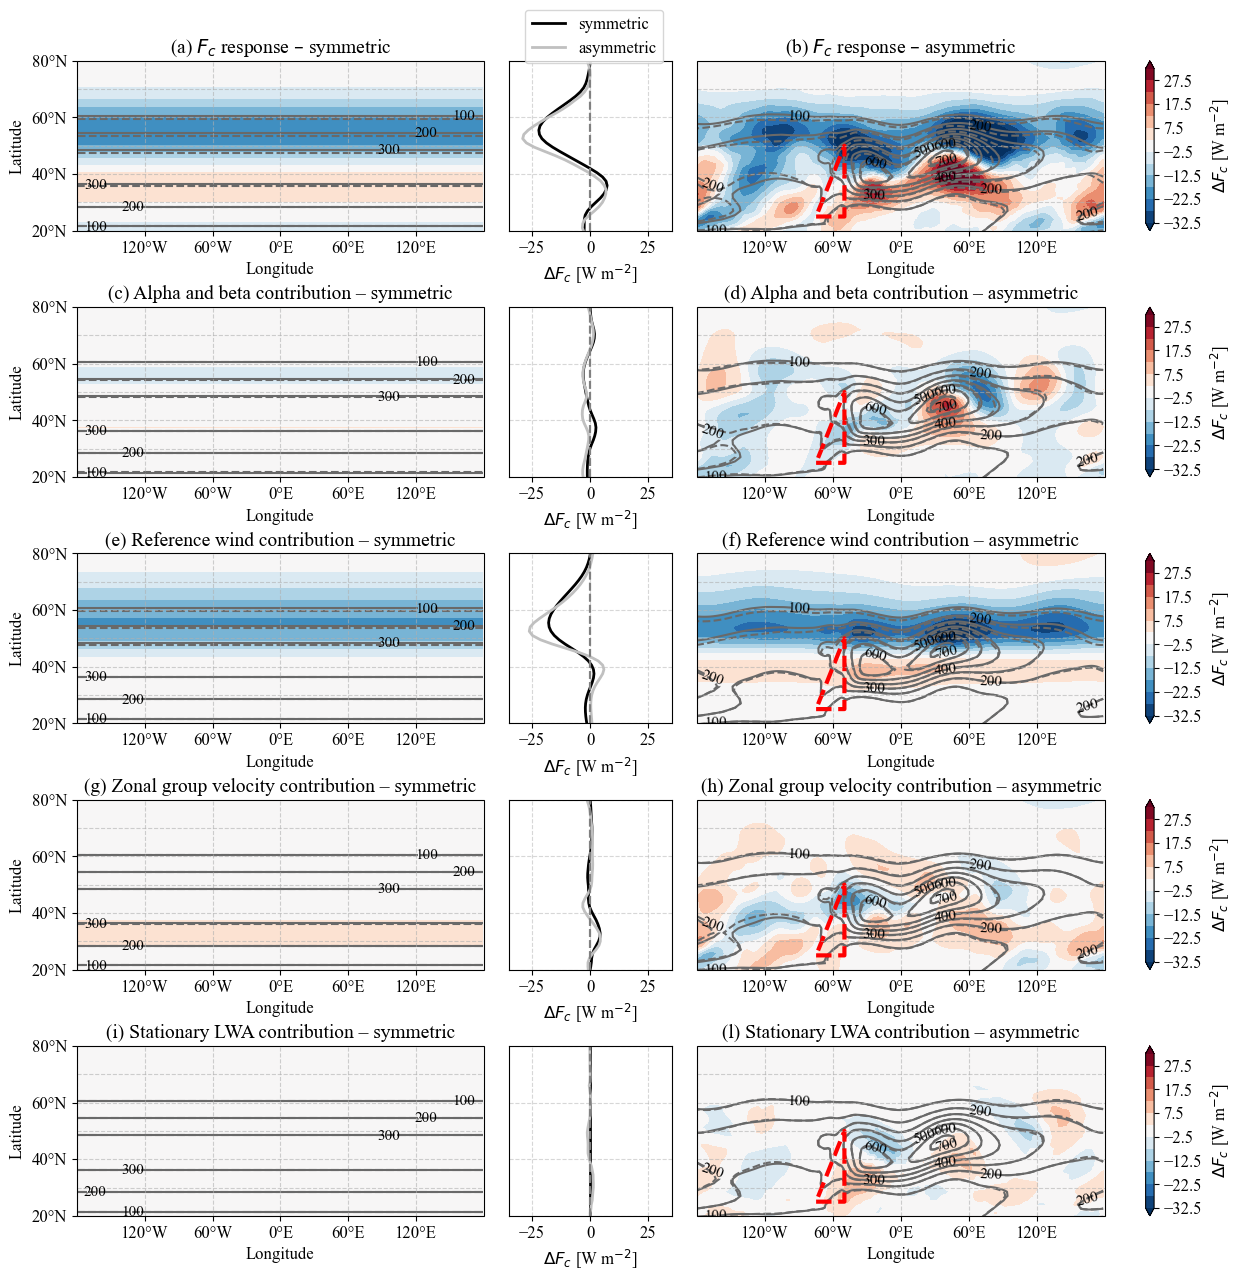

In [17]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs

plt.rcParams['font.size'] = 12
plt.rcParams['hatch.color'] = 'k'
plt.rcParams['hatch.linewidth'] = 0.6

# ==================================================
# Settings for significance
# ==================================================
Z_SIG = 1.96   # 95% two-sided
N_EFF = 1      # if *_std is the interannual spread, use number of years/members
               # (std of the mean = std/sqrt(N_EFF)); keep 1 if *_std is already
               # the uncertainty of the mean

LAT_MIN, LAT_MAX = 20, 80
ASPECT = 2.5

# dataset ('A' or 'B') feeding each slot of compute_FC: (c, u_0, alpha, beta, qslwa)
SPEC = {
    'total': ('B', 'B', 'B', 'B', 'B'),
    'ab':    ('A', 'A', 'B', 'B', 'A'),
    'u0':    ('A', 'B', 'A', 'A', 'A'),
    'cg':    ('B', 'A', 'A', 'A', 'A'),
    'q':     ('A', 'A', 'A', 'A', 'B'),
}
BASE = ('A',) * 5


# ==================================================
# Helpers
# ==================================================
def broadcast_zonal(field, ds_ref):
    return field.mean('lon').broadcast_like(ds_ref)


def _grad_coefs(dsets, spec, lat):
    """dF/d(elementary variable), keyed by (dataset, variable).
    Elementary variables: zgv (c_g), u_0, alpha, beta, qslwa."""
    sc, su, sa, sb, sq = spec
    c  = dsets[sc]['zgv']
    u0 = dsets[su]['u_0']
    al = dsets[sa]['alpha']
    be = dsets[sb]['beta']
    q  = dsets[sq]['qslwa']
    cosphi = np.cos(np.deg2rad(lat))

    u  = c + u0 + be - 2*al*q
    Fu = u*cosphi/(2*al)                              # dF/du  (= dF/dc_g = dF/du_0 = dF/dbeta)
    Fa = -u**2*cosphi/(4*al**2) - 2*q*Fu              # dF/dalpha at fixed beta
    Fq = -2*al*Fu                                     # dF/dqslwa = -u*cosphi

    coef = {}
    def add(key, val):
        coef[key] = coef.get(key, 0) + val

    add((sc, 'zgv'),    Fu)
    add((su, 'u_0'),    Fu)
    add((sa, 'alpha'),  Fa)
    add((sb, 'beta'),   Fu)
    add((sq, 'qslwa'),  Fq)
    return coef


def propagate_sigma(ds_a, ds_b, zonal):
    """Returns {term: (sigma_map[lat,lon], sigma_xsec[lat])} of the plotted difference."""
    ds   = {'A': ds_a, 'B': ds_b}
    lat  = ds_a['lat']
    nlon = ds_a.sizes['lon']
    ref  = ds_a['zgv']
    base = _grad_coefs(ds, BASE, lat)

    out = {}
    for k, spec in SPEC.items():
        g = _grad_coefs(ds, spec, lat)
        var = 0

        # alpha and beta of the same dataset are not independent:
        # beta_std = lwa_mean * alpha_std  ->  delta_beta = lwa_mean * delta_alpha
        for d in ('A', 'B'):
            ca = g.get((d, 'alpha'), 0) - base.get((d, 'alpha'), 0)
            cb = g.get((d, 'beta'),  0) - base.get((d, 'beta'),  0)
            c_tot = ca + ds[d]['lwa_mean'] * cb
            var = var + (c_tot * ds[d]['alpha_std'] / np.sqrt(N_EFF))**2

        # independent variables: zgv, u_0, qslwa
        for key in set(g) | set(base):
            if key[1] in ('alpha', 'beta'):
                continue
            coef  = g.get(key, 0) - base.get(key, 0)
            sigma = ds[key[0]][key[1] + '_std'] / np.sqrt(N_EFF)
            var   = var + (coef*sigma)**2
        var = var.broadcast_like(ref)

        # zonal mean of the difference, errors independent between longitudes
        sig_x = np.sqrt(var.mean('lon') / nlon)
        sig_m = sig_x.broadcast_like(ref) if zonal else np.sqrt(var)
        out[k] = (sig_m, sig_x)
    return out
    
def add_hatch(ax, lon, lat, diff, sigma, hatch='...', where='significant'):
    """Hatch non-significant points (default) or significant ones (where='significant')."""
    sig_mask = np.abs(diff) > Z_SIG*sigma
    if where == 'not_significant':
        # NaNs in diff/sigma are not hatched
        mask = (~sig_mask & diff.notnull() & sigma.notnull()).astype(float).values
    else:
        mask = sig_mask.astype(float).fillna(0).values
    if mask.any():
        ax.contourf(lon, lat, mask, levels=[0.5, 1.5], colors='none',
                    hatches=[hatch], transform=ccrs.PlateCarree())

# ==================================================
# Figure layout
# ==================================================
fig = plt.figure(figsize=(18, 15))

gs = gridspec.GridSpec(
    nrows=5,
    ncols=5,
    width_ratios=[6.0, 0.3, 1.2, 0.01, 6.0],
    hspace=0.45,
    wspace=-0.3
)

titles  = ['symmetric', 'asymmetric']
letters = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)', '(i)', '(l)']
colors  = ['k', 'silver']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)

lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

levels = np.arange(100, 1300, 100)
levels_diff =  np.arange(-32.5, 33, 5)


ax_xsec = []
term_keys = ['ab', 'u0', 'cg', 'q']

# ==================================================
# Loop symmetric / asymmetric
# ==================================================
for i in range(2):

    XSEC_COL = 2
    MAP_COL  = 0 if i == 0 else 4

    ds_a = ds_clims[i*2]
    ds_b = ds_clims[i*2+1]

    # error propagation for all terms of this case
    sig = propagate_sigma(ds_a, ds_b, zonal=(i == 0))

    # ==================================================
    # ROW 0 — $F_c$ response
    # ==================================================
    if i == 0:
        ax_xsec_total = fig.add_subplot(gs[0, XSEC_COL])

    ax_map = fig.add_subplot(gs[0, MAP_COL], projection=proj, sharey=ax_xsec_total)

    FC_b = compute_FC(ds_b['zgv'], ds_b['u_0'], ds_b['alpha'], ds_b['beta'], ds_b['qslwa'])
    FC_a = compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])

    if i == 0:
        FC_b = broadcast_zonal(FC_b, ds_a)
        FC_a = broadcast_zonal(FC_a, ds_a)

    total_diff = FC_b - FC_a

    ax_map.set_title(f'{letters[i]} $F_c$ response – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, FC_a,
                        levels=levels, colors='dimgray')

    ax_map.contour(ds_b.lon, ds_b.lat, FC_b,
                   levels=levels, colors='dimgray',
                   linestyles='dashed')

    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    sh = ax_map.contourf(ds_a.lon, ds_a.lat, total_diff,
                         levels=levels_diff,
                         cmap='RdBu_r', extend='both')

    # hatching: |dFc| > Z_SIG * sigma
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, total_diff, sig['total'][0])

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta F_c$ [W m$^{-2}$]')

    if i > 0:
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
    ax_map.set_aspect(ASPECT)   

    ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
    ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20, 40, 60, 80])
        ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

    xsec = total_diff.mean('lon').values

    ax_xsec_total.plot(xsec, ds_a.lat.values, color=colors[i], lw=2, label=titles[i])
    sx = sig['total'][1].values
    ax_xsec_total.fill_betweenx(ds_a.lat.values, xsec - Z_SIG*sx, xsec + Z_SIG*sx,
                                color=colors[i], alpha=0.25, lw=0)
    ax_xsec_total.axvline(0, color='gray', ls='--')
    ax_xsec_total.set_xlim(-35, 35)
    ax_xsec_total.set_xlabel(r'$\Delta F_c$ [W m$^{-2}$]')
    ax_xsec_total.grid(True, ls='--', alpha=0.5)
    ax_xsec_total.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_total.get_yticklabels(), visible=False)

    if i == 1:
        ax_xsec_total.legend(loc='upper right', bbox_to_anchor=(1.0, 1.35))

    # ==================================================
    # FC_terms definitions
    # ==================================================
    FC_terms = [
        ('Alpha and beta contribution',
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_b['alpha'], ds_b['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Reference wind contribution',
         compute_FC(ds_a['zgv'], ds_b['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Zonal group velocity contribution',
         compute_FC(ds_b['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Stationary LWA contribution',
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_b['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']))
    ]

    # ==================================================
    # ROWS 1–4 — linear terms
    # ==================================================
    for r, (label, field_b, field_a) in enumerate(FC_terms):

        key = term_keys[r]

        if i == 0:
            ax_xsec.append(fig.add_subplot(gs[r+1, XSEC_COL]))

        ax_map = fig.add_subplot(gs[r+1, MAP_COL], projection=proj, sharey=ax_xsec[r])

        if i == 0:
            field_b = broadcast_zonal(field_b, ds_a)
            field_a = broadcast_zonal(field_a, ds_a)

        fc_diff = field_b - field_a

        ax_map.set_title(f'{letters[2*(r+1) + i]} {label} – {titles[i]}')

        c1 = ax_map.contour(ds_a.lon, ds_a.lat, field_a,
                            levels=levels, colors='dimgray')

        ax_map.contour(ds_b.lon, ds_b.lat, field_b,
                       levels=levels, colors='dimgray',
                       linestyles='dashed')

        ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

        sh = ax_map.contourf(ds_a.lon, ds_a.lat, fc_diff,
                             levels=levels_diff,
                             cmap='RdBu_r', extend='both')

        # hatching: |dFc| > Z_SIG * sigma
        #add_hatch(ax_map, ds_a.lon, ds_a.lat, fc_diff, sig[key][0])

        if i > 0:
            fig.colorbar(sh, ax=ax_map, label=r'$\Delta F_c$ [W m$^{-2}$]')

        if i > 0:
            ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

        ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
        ax_map.set_aspect(ASPECT)
        
        ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
        ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
        ax_map.set_xlabel('Longitude')

        if i == 0:
            ax_map.set_yticks([20, 40, 60, 80])
            ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
            ax_map.set_ylabel('Latitude')
        else:
            plt.setp(ax_map.get_yticklabels(), visible=False)

        ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

        xsec = fc_diff.mean('lon').values

        if r == 3 and i == 0:
            xsec = np.zeros_like(xsec)

        ax_xsec[r].plot(xsec, ds_a.lat.values, color=colors[i], lw=2, label=titles[i])
        if not (r == 3 and i == 0):
            sx = sig[key][1].values
            ax_xsec[r].fill_betweenx(ds_a.lat.values, xsec - Z_SIG*sx, xsec + Z_SIG*sx,
                                     color=colors[i], alpha=0.25, lw=0)
        ax_xsec[r].axvline(0, color='gray', ls='--')
        ax_xsec[r].set_xlim(-35, 35)
        ax_xsec[r].set_xlabel(r'$\Delta F_c$ [W m$^{-2}$]')
        ax_xsec[r].grid(True, ls='--', alpha=0.5)
        ax_xsec[r].tick_params(axis='y', length=0)
        plt.setp(ax_xsec[r].get_yticklabels(), visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure_6', dpi=500, bbox_inches='tight')
plt.show()

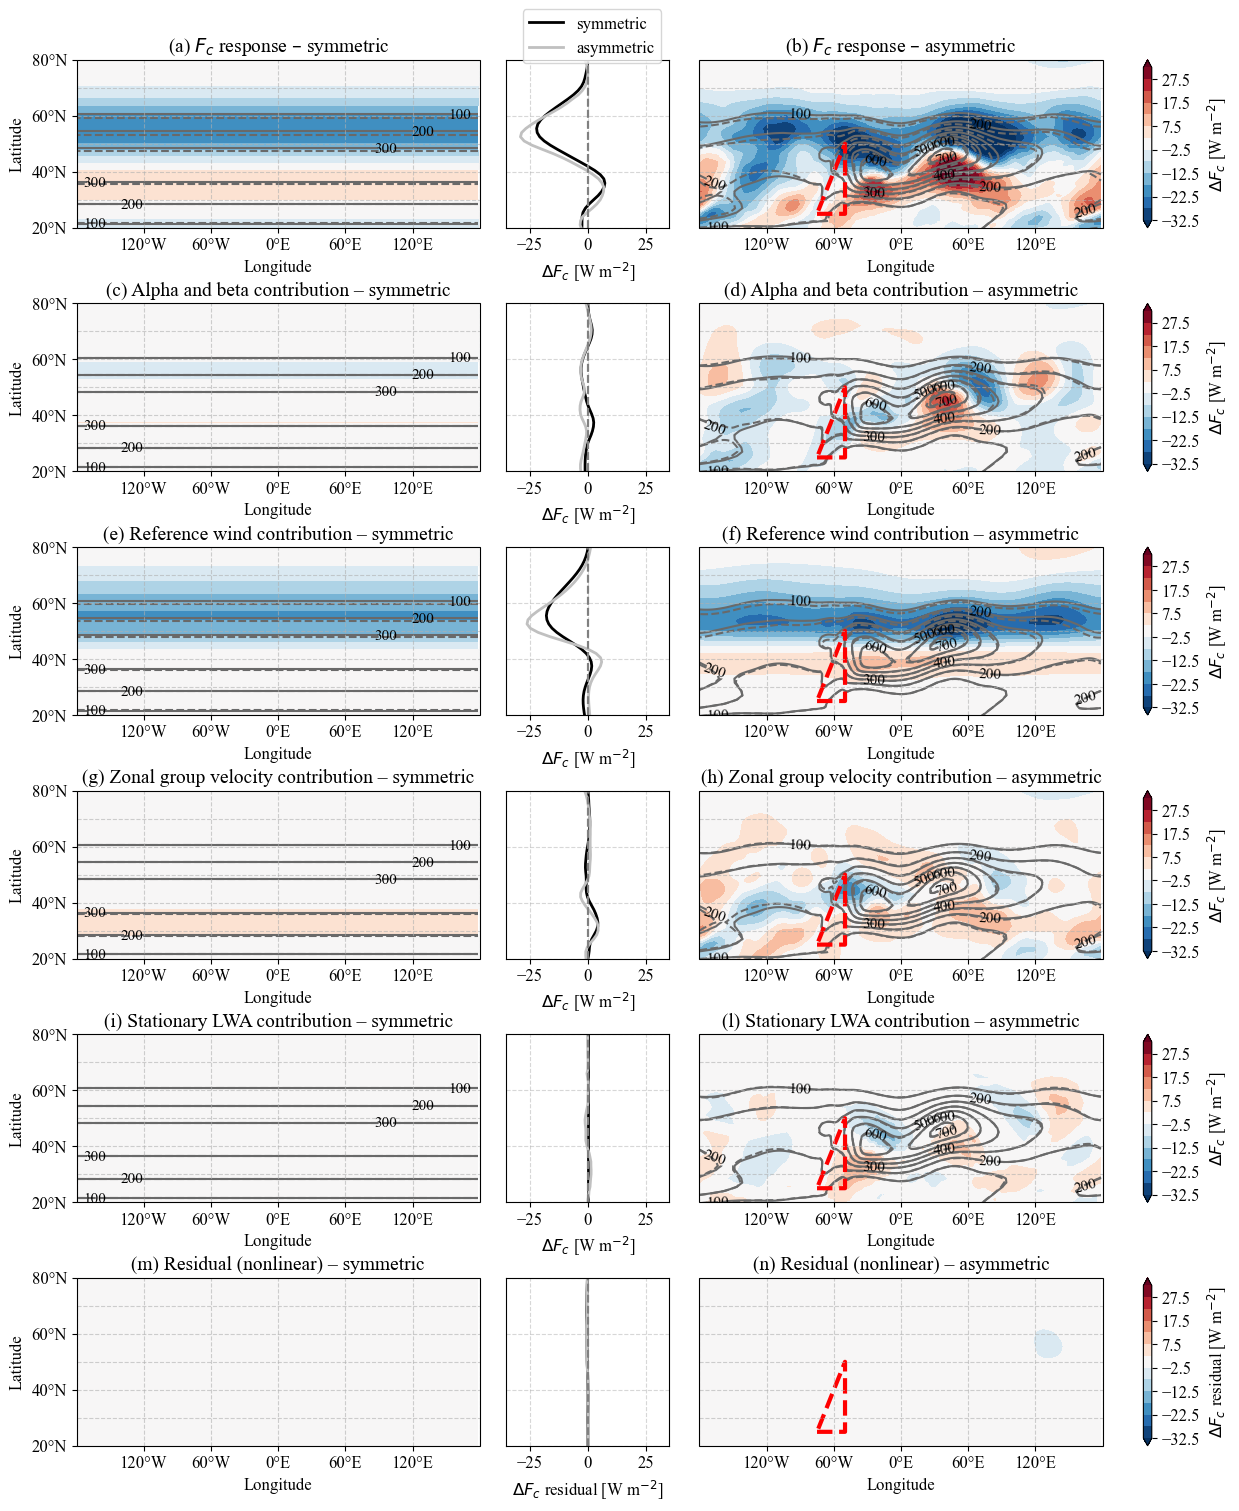

In [15]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs

plt.rcParams['font.size'] = 12
plt.rcParams['hatch.color'] = 'k'
plt.rcParams['hatch.linewidth'] = 0.6

# Assumes ds_clims and compute_FC are already defined.

# ==================================================
# Settings for significance
# ==================================================
Z_SIG = 1.96   # 95% two-sided
N_EFF = 1      # if *_std is the interannual spread, use number of years/members
               # (std of the mean = std/sqrt(N_EFF)); keep 1 if *_std is already
               # the uncertainty of the mean

LAT_MIN, LAT_MAX = 20, 80
ASPECT = 2.5

# dataset ('A' or 'B') feeding each slot of compute_FC: (c, u_0, alpha, beta, qslwa)
SPEC = {
    'total': ('B', 'B', 'B', 'B', 'B'),
    'ab':    ('A', 'A', 'B', 'B', 'A'),
    'u0':    ('A', 'B', 'A', 'A', 'A'),
    'cg':    ('B', 'A', 'A', 'A', 'A'),
    'q':     ('A', 'A', 'A', 'A', 'B'),
}
BASE = ('A',) * 5


# ==================================================
# Helpers
# ==================================================
def broadcast_zonal(field, ds_ref):
    return field.mean('lon').broadcast_like(ds_ref)


def _grad_coefs(dsets, spec, lat):
    """dF/d(elementary variable), keyed by (dataset, variable).
    Elementary variables: zgv (c_g), u_0, alpha, beta, qslwa."""
    sc, su, sa, sb, sq = spec
    c  = dsets[sc]['zgv']
    u0 = dsets[su]['u_0']
    al = dsets[sa]['alpha']
    be = dsets[sb]['beta']
    q  = dsets[sq]['qslwa']
    cosphi = np.cos(np.deg2rad(lat))

    u  = c + u0 + be - 2*al*q
    Fu = u*cosphi/(2*al)                              # dF/du  (= dF/dc_g = dF/du_0 = dF/dbeta)
    Fa = -u**2*cosphi/(4*al**2) - 2*q*Fu              # dF/dalpha at fixed beta
    Fq = -2*al*Fu                                     # dF/dqslwa = -u*cosphi

    coef = {}
    def add(key, val):
        coef[key] = coef.get(key, 0) + val

    add((sc, 'zgv'),    Fu)
    add((su, 'u_0'),    Fu)
    add((sa, 'alpha'),  Fa)
    add((sb, 'beta'),   Fu)
    add((sq, 'qslwa'),  Fq)
    return coef


def propagate_sigma(ds_a, ds_b, zonal):
    """Returns {term: (sigma_map[lat,lon], sigma_xsec[lat])} of the plotted difference."""
    ds   = {'A': ds_a, 'B': ds_b}
    lat  = ds_a['lat']
    nlon = ds_a.sizes['lon']
    ref  = ds_a['zgv']
    base = _grad_coefs(ds, BASE, lat)

    out = {}
    for k, spec in SPEC.items():
        g = _grad_coefs(ds, spec, lat)
        var = 0

        # alpha and beta of the same dataset are not independent:
        # beta_std = lwa_mean * alpha_std  ->  delta_beta = lwa_mean * delta_alpha
        for d in ('A', 'B'):
            ca = g.get((d, 'alpha'), 0) - base.get((d, 'alpha'), 0)
            cb = g.get((d, 'beta'),  0) - base.get((d, 'beta'),  0)
            c_tot = ca + ds[d]['lwa_mean'] * cb
            var = var + (c_tot * ds[d]['alpha_std'] / np.sqrt(N_EFF))**2

        # independent variables: zgv, u_0, qslwa
        for key in set(g) | set(base):
            if key[1] in ('alpha', 'beta'):
                continue
            coef  = g.get(key, 0) - base.get(key, 0)
            sigma = ds[key[0]][key[1] + '_std'] / np.sqrt(N_EFF)
            var   = var + (coef*sigma)**2
        var = var.broadcast_like(ref)

        # zonal mean of the difference, errors independent between longitudes
        sig_x = np.sqrt(var.mean('lon') / nlon)
        sig_m = sig_x.broadcast_like(ref) if zonal else np.sqrt(var)
        out[k] = (sig_m, sig_x)
    return out


def add_hatch(ax, lon, lat, diff, sigma, hatch='...', where='significant'):
    """Hatch non-significant points (default) or significant ones (where='significant')."""
    sig_mask = np.abs(diff) > Z_SIG*sigma
    if where == 'not_significant':
        # NaNs in diff/sigma are not hatched
        mask = (~sig_mask & diff.notnull() & sigma.notnull()).astype(float).values
    else:
        mask = sig_mask.astype(float).fillna(0).values
    if mask.any():
        ax.contourf(lon, lat, mask, levels=[0.5, 1.5], colors='none',
                    hatches=[hatch], transform=ccrs.PlateCarree())


# ==================================================
# Figure layout
# ==================================================
fig = plt.figure(figsize=(18, 18))

gs = gridspec.GridSpec(
    nrows=6,
    ncols=5,
    width_ratios=[6.0, 0.3, 1.2, 0.01, 6.0],
    hspace=0.45,
    wspace=-0.3
)

titles  = ['symmetric', 'asymmetric']
letters = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)', '(i)', '(l)', '(m)', '(n)']
colors  = ['k', 'silver']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)

lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

levels = np.arange(100, 1300, 100)
levels_diff = np.arange(-32.5, 33, 5)

ax_xsec = []
term_keys = ['ab', 'u0', 'cg', 'q']

# ==================================================
# Loop symmetric / asymmetric
# ==================================================
for i in range(2):

    XSEC_COL = 2
    MAP_COL  = 0 if i == 0 else 4

    ds_a = ds_clims[i*2]
    ds_b = ds_clims[i*2+1]

    # error propagation for all terms of this case
    sig = propagate_sigma(ds_a, ds_b, zonal=(i == 0))

    # ==================================================
    # ROW 0 — F_c response
    # ==================================================
    if i == 0:
        ax_xsec_total = fig.add_subplot(gs[0, XSEC_COL])

    ax_map = fig.add_subplot(gs[0, MAP_COL], projection=proj, sharey=ax_xsec_total)

    FC_b = compute_FC(ds_b['zgv'], ds_b['u_0'], ds_b['alpha'], ds_b['beta'], ds_b['qslwa'])
    FC_a = compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])

    if i == 0:
        FC_b = broadcast_zonal(FC_b, ds_a)
        FC_a = broadcast_zonal(FC_a, ds_a)

    total_diff = FC_b - FC_a

    ax_map.set_title(f'{letters[i]} $F_c$ response – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, FC_a,
                        levels=levels, colors='dimgray')

    ax_map.contour(ds_b.lon, ds_b.lat, FC_b,
                   levels=levels, colors='dimgray',
                   linestyles='dashed')

    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    sh = ax_map.contourf(ds_a.lon, ds_a.lat, total_diff,
                         levels=levels_diff,
                         cmap='RdBu_r', extend='both')

    # hatching: |dFc| > Z_SIG * sigma
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, total_diff, sig['total'][0])

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta F_c$ [W m$^{-2}$]')

    if i > 0:
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
    ax_map.set_aspect(ASPECT)

    ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
    ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20, 40, 60, 80])
        ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

    xsec = total_diff.mean('lon').values

    ax_xsec_total.plot(xsec, ds_a.lat.values, color=colors[i], lw=2, label=titles[i])
    sx = sig['total'][1].values
    ax_xsec_total.fill_betweenx(ds_a.lat.values, xsec - Z_SIG*sx, xsec + Z_SIG*sx,
                                color=colors[i], alpha=0.25, lw=0)
    ax_xsec_total.axvline(0, color='gray', ls='--')
    ax_xsec_total.set_xlim(-35, 35)
    ax_xsec_total.set_xlabel(r'$\Delta F_c$ [W m$^{-2}$]')
    ax_xsec_total.grid(True, ls='--', alpha=0.5)
    ax_xsec_total.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_total.get_yticklabels(), visible=False)

    if i == 1:
        ax_xsec_total.legend(loc='upper right', bbox_to_anchor=(1.0, 1.35))

    # ==================================================
    # FC_terms definitions
    # ==================================================
    FC_terms = [
        ('Alpha and beta contribution',
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_b['alpha'], ds_b['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Reference wind contribution',
         compute_FC(ds_a['zgv'], ds_b['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Zonal group velocity contribution',
         compute_FC(ds_b['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa'])),

        ('Stationary LWA contribution',
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_b['qslwa']),
         compute_FC(ds_a['zgv'], ds_a['u_0'], ds_a['alpha'], ds_a['beta'], ds_a['qslwa']))
    ]

    # ==================================================
    # ROWS 1–4 — linear terms
    # ==================================================
    term_diffs = []

    for r, (label, field_b, field_a) in enumerate(FC_terms):

        key = term_keys[r]

        if i == 0:
            ax_xsec.append(fig.add_subplot(gs[r+1, XSEC_COL]))

        ax_map = fig.add_subplot(gs[r+1, MAP_COL], projection=proj, sharey=ax_xsec[r])

        if i == 0:
            field_b = broadcast_zonal(field_b, ds_a)
            field_a = broadcast_zonal(field_a, ds_a)

        fc_diff = field_b - field_a
        term_diffs.append(fc_diff)

        ax_map.set_title(f'{letters[2*(r+1) + i]} {label} – {titles[i]}')

        c1 = ax_map.contour(ds_a.lon, ds_a.lat, field_a,
                            levels=levels, colors='dimgray')

        ax_map.contour(ds_b.lon, ds_b.lat, field_b,
                       levels=levels, colors='dimgray',
                       linestyles='dashed')

        ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

        sh = ax_map.contourf(ds_a.lon, ds_a.lat, fc_diff,
                             levels=levels_diff,
                             cmap='RdBu_r', extend='both')

        # hatching: |dFc| > Z_SIG * sigma
        #add_hatch(ax_map, ds_a.lon, ds_a.lat, fc_diff, sig[key][0])

        if i > 0:
            fig.colorbar(sh, ax=ax_map, label=r'$\Delta F_c$ [W m$^{-2}$]')

        if i > 0:
            ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

        ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
        ax_map.set_aspect(ASPECT)

        ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
        ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
        ax_map.set_xlabel('Longitude')

        if i == 0:
            ax_map.set_yticks([20, 40, 60, 80])
            ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
            ax_map.set_ylabel('Latitude')
        else:
            plt.setp(ax_map.get_yticklabels(), visible=False)

        ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

        xsec = fc_diff.mean('lon').values

        if r == 3 and i == 0:
            xsec = np.zeros_like(xsec)

        ax_xsec[r].plot(xsec, ds_a.lat.values, color=colors[i], lw=2, label=titles[i])
        if not (r == 3 and i == 0):
            sx = sig[key][1].values
            ax_xsec[r].fill_betweenx(ds_a.lat.values, xsec - Z_SIG*sx, xsec + Z_SIG*sx,
                                     color=colors[i], alpha=0.25, lw=0)
        ax_xsec[r].axvline(0, color='gray', ls='--')
        ax_xsec[r].set_xlim(-35, 35)
        ax_xsec[r].set_xlabel(r'$\Delta F_c$ [W m$^{-2}$]')
        ax_xsec[r].grid(True, ls='--', alpha=0.5)
        ax_xsec[r].tick_params(axis='y', length=0)
        plt.setp(ax_xsec[r].get_yticklabels(), visible=False)

    # ==================================================
    # ROW 5 — residual: total - sum of linear terms
    # ==================================================
    residual = total_diff - sum(term_diffs)

    if i == 0:
        ax_xsec_res = fig.add_subplot(gs[5, XSEC_COL])

    ax_map = fig.add_subplot(gs[5, MAP_COL], projection=proj, sharey=ax_xsec_res)

    ax_map.set_title(f'{letters[10 + i]} Residual (nonlinear) – {titles[i]}')

    sh = ax_map.contourf(ds_a.lon, ds_a.lat, residual,
                         levels=levels_diff, cmap='RdBu_r', extend='both')

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta F_c$ residual [W m$^{-2}$]')
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
    ax_map.set_aspect(ASPECT)

    ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
    ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20, 40, 60, 80])
        ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

    xsec = residual.mean('lon').values
    ax_xsec_res.plot(xsec, ds_a.lat.values, color=colors[i], lw=2, label=titles[i])
    ax_xsec_res.axvline(0, color='gray', ls='--')
    ax_xsec_res.set_xlim(-35, 35)
    ax_xsec_res.set_xlabel(r'$\Delta F_c$ residual [W m$^{-2}$]')
    ax_xsec_res.grid(True, ls='--', alpha=0.5)
    ax_xsec_res.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_res.get_yticklabels(), visible=False)

# --------------------------------------------------
plt.show()